In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100

df = pd.DataFrame({
    "Temperature": np.round(np.random.uniform(5, 35, n), 2),
    "Pressure": np.round(np.random.uniform(990, 1035, n), 2),
    "Humidity": np.round(np.random.uniform(25, 100, n), 2),
    "Vaccum": np.round(np.random.uniform(25, 80, n), 2)
})

# Generate Electrical Output (Target)
df["Energy"] = np.round(
    500
    - 1.5 * df["Temperature"]
    + 0.03 * df["Pressure"]
    - 0.4 * df["Humidity"]
    + 0.25 * df["Vaccum"]
    + np.random.normal(0, 2, n),
    2
)

 

In [3]:
df.isnull().sum()

df['Vaccum'].duplicated().sum()


import seaborn as sns
import matplotlib.pyplot as plt







In [68]:
df.tail()

df.describe()

corr=df.corr()



<Axes: title={'center': 'correalation matrix '}>

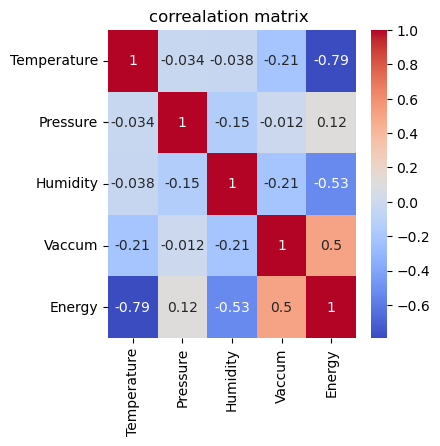

In [69]:
# correlation heartmap
plt.figure(figsize=(4,4))
plt.title('correalation matrix ')
sns.heatmap(corr,annot=True,cmap='coolwarm')
 

<Axes: xlabel='Vaccum', ylabel='Count'>

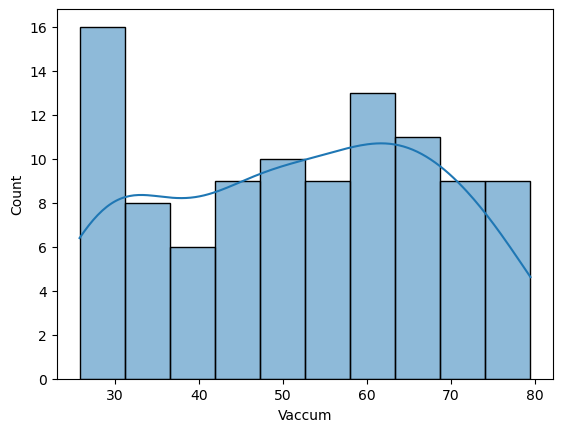

In [80]:
# histogram 

 

sns.histplot(df['Vaccum'],bins=10,kde=True)


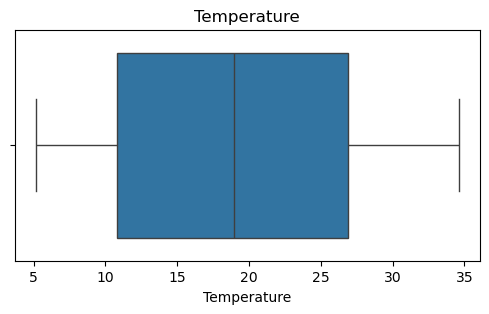

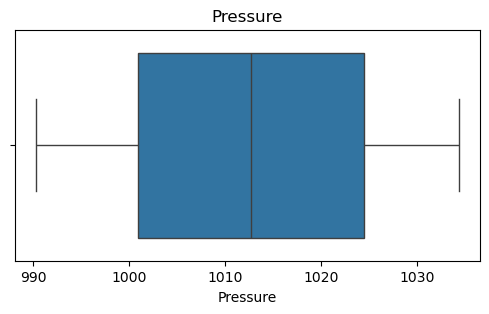

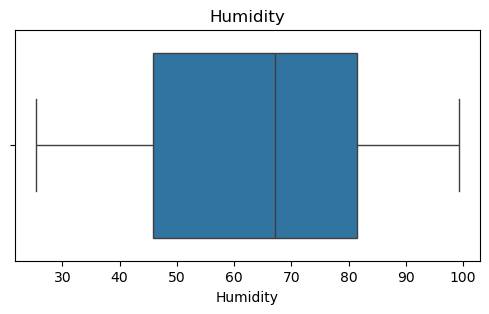

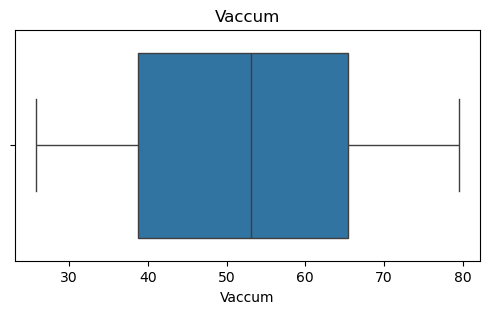

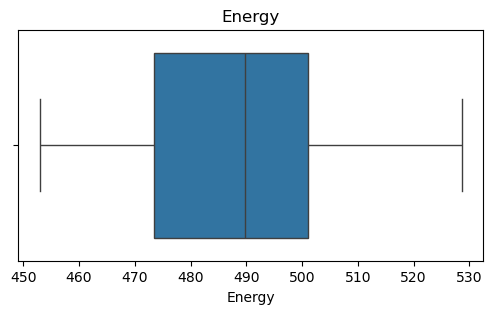

In [4]:
# box plot 


for col in df.columns:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()


In [93]:
df.dtypes

Temperature    float64
Pressure       float64
Humidity       float64
Vaccum         float64
Energy         float64
dtype: object

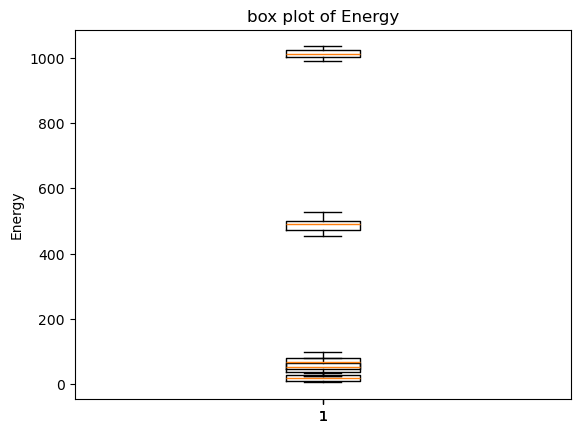

In [5]:
for i in df.columns:
    plt.boxplot(df[i])

    plt.Figure(figsize=(6,4))

    plt.title(f"box plot of {i}")
    plt.ylabel(i)

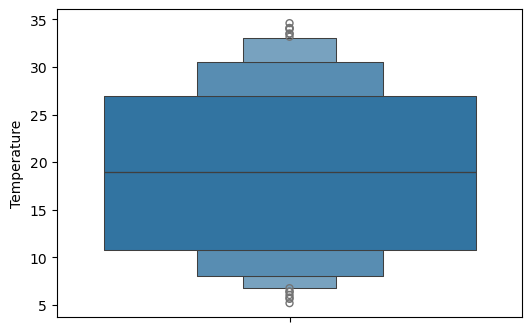

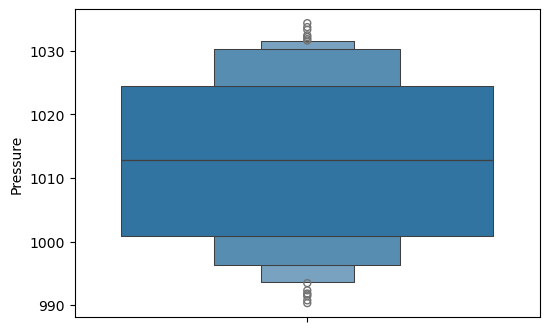

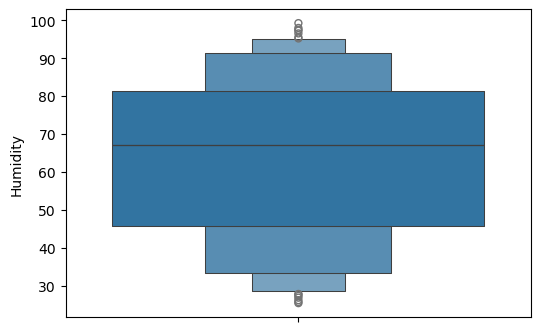

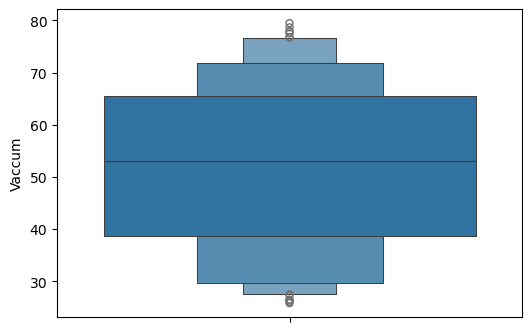

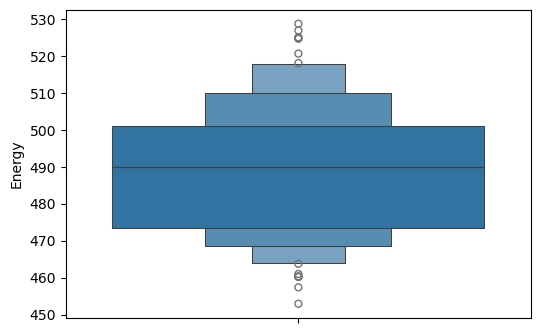

In [100]:
for i in df.columns:

    plt.figure(figsize=(6,4))
    sns.boxenplot(y=df[i])

In [113]:
df

,Temperature,Pressure,Humidity,Vaccum,Energy
0,16.24,991.41,73.15,27.84,485.69
1,33.52,1018.64,31.31,54.22,481.35
2,26.96,1004.15,37.12,54.73,489.88
3,22.96,1012.89,92.39,60.06,473.39
4,9.68,1030.84,70.48,64.94,505.10
...,...,...,...,...,...
95,19.81,1005.71,64.17,76.19,494.86
96,20.68,1022.67,82.75,72.21,486.04
97,17.83,1030.37,41.19,48.59,497.59
98,5.76,1029.92,71.72,66.30,507.08


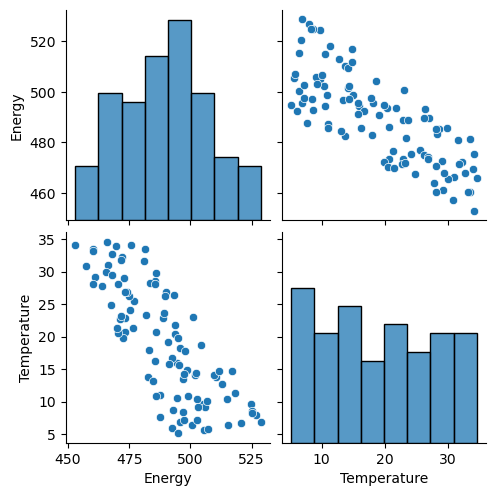

In [114]:
# pair plots
sns.pairplot(df[['Energy','Temperature']])

<Axes: xlabel='Temperature', ylabel='Pressure'>

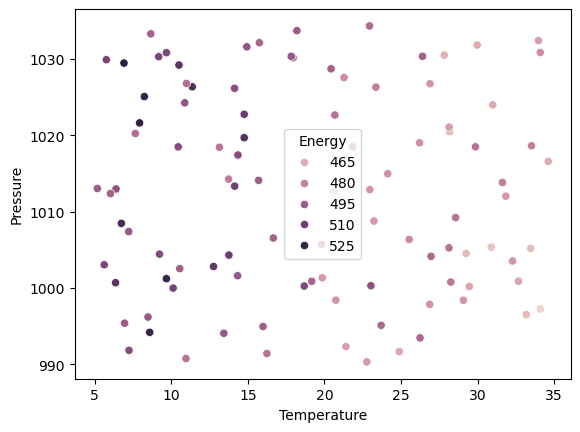

In [130]:

sns.scatterplot(
    x='Temperature',
    y='Pressure',
    hue='Energy',
    data=df
)


In [131]:
Q1 = df.quantile(0.25)

Q3 = df.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR

upper = Q3 + 1.5 * IQR

outliers = ((df < lower) | (df > upper)).sum()

print(outliers)

Temperature    0
Pressure       0
Humidity       0
Vaccum         0
Energy         0
dtype: int64


In [6]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100

df = pd.DataFrame({
    "Temperature": np.round(np.random.uniform(5, 35, n), 2),
    "Pressure": np.round(np.random.uniform(990, 1035, n), 2),
    "Humidity": np.round(np.random.uniform(25, 100, n), 2),
    "Vaccum": np.round(np.random.uniform(25, 80, n), 2)
})

# Generate Electrical Output (Target)
df["Energy"] = np.round(
    500
    - 1.5 * df["Temperature"]
    + 0.03 * df["Pressure"]
    - 0.4 * df["Humidity"]
    + 0.25 * df["Vaccum"]
    + np.random.normal(0, 2, n),
    2
)

 

In [133]:
df

,Temperature,Pressure,Humidity,Vaccum,Energy
0,16.24,991.41,73.15,27.84,485.69
1,33.52,1018.64,31.31,54.22,481.35
2,26.96,1004.15,37.12,54.73,489.88
3,22.96,1012.89,92.39,60.06,473.39
4,9.68,1030.84,70.48,64.94,505.10
...,...,...,...,...,...
95,19.81,1005.71,64.17,76.19,494.86
96,20.68,1022.67,82.75,72.21,486.04
97,17.83,1030.37,41.19,48.59,497.59
98,5.76,1029.92,71.72,66.30,507.08


In [8]:
X=df.iloc[:,0:4]

y=df['Energy']




In [9]:
# train test split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=88)
X_train
X_test
y_test
y_train

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [10]:
#perceptron model 

import keras 
import tensorflow as tf
from keras.models import Sequential

from keras.layers import Dense,Input






In [11]:
# desine to perceptron model
p_model=Sequential()


#add_layer

p_model.add(Dense(input_dim=4,units=1,activation='linear',kernel_initializer='uniform'))
p_model.add(Dense(units=1,activation='linear',kernel_initializer='uniform'))



#compile_model
p_model.compile(optimizer='adam',loss='mean_squared_error')

# fit and train data

p_model.fit(X_train,y_train,batch_size=32,epochs=100)






C:\Users\vilas\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 240626.2500 
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 240623.1562
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 240620.0938
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 240617.0312
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 240613.9219
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 240610.8281 
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 240607.7031
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 240604.5312
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 240601.3438
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 240598.1250
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 240594.8750
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 240591.6250
Epoch 13/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 240588.2969
Epoch 14/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 240585.0000
Epoch 15/100
3

In [12]:
# adding more hidden layer 

p_model=Sequential()
p_model.add(Input(shape=(4,)))     #4 feature

p_model.add(Dense(16,activation='relu',kernel_initializer='uniform'))     
p_model.add(Dense(8,activation='relu'))

p_model.add(Dense(1,activation='linear'))     



 


#compile_model
p_model.compile(optimizer='adam',loss='mean_squared_error')

# fit and train data

p_model.fit(X_train,y_train,batch_size=32,epochs=100)






Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 240653.8750 
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 240636.0000
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 240619.2500
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 240604.1250
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 240591.2812
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 240579.9531
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 240569.5469
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 240559.2500
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 240548.5000
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 240537.2188
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 240525.4062
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 240512.5938
Epoch 13/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 240499.3438
Epoch 14/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 240485.3750
Epoch 15/100
3

In [234]:
y_pred=p_model.predict(X_train)

#Calculating train data

from sklearn.metrics import mean_squared_error
 
train_mse=mean_squared_error(y_train,y_pred)
train_rmse=np.sqrt(train_mse)

print('train_RMSE:',train_rmse)


#calculating test_data
y_pred_test=p_model.predict(X_test)
test_mse=mean_squared_error(y_test,y_pred_test)
test_rmse=np.sqrt(test_mse)
print('test RMSE:',test_rmse)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
train_RMSE: 474.61074049619253
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
test RMSE: 472.16019814290433


In [235]:
df

,Temperature,Pressure,Humidity,Vaccum,Energy
0,16.24,991.41,73.15,27.84,485.69
1,33.52,1018.64,31.31,54.22,481.35
2,26.96,1004.15,37.12,54.73,489.88
3,22.96,1012.89,92.39,60.06,473.39
4,9.68,1030.84,70.48,64.94,505.10
...,...,...,...,...,...
95,19.81,1005.71,64.17,76.19,494.86
96,20.68,1022.67,82.75,72.21,486.04
97,17.83,1030.37,41.19,48.59,497.59
98,5.76,1029.92,71.72,66.30,507.08


In [239]:
fut=pd.DataFrame({"Temperature":[20],"Pressure":820,"Humidity":70,"Vaccum":60})
fut
p_model.predict(fut)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


array([[3798.5903]], dtype=float32)

In [208]:
p_model.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 677 (2.65 KB)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 452 (1.77 KB)

In [209]:
# number of neuron
for i in p_model.layers:
    print(i.units)

16
8
1


In [210]:
# view weight
for i in p_model.layers:
    print(i.get_weights())

[array([[ 4.02060807e-01, -3.20691019e-01,  2.55353481e-01,
         6.51006773e-03, -3.66109563e-03, -3.14679116e-01,
        -6.50476897e-04,  5.87964372e-04, -4.41204697e-01,
        -4.56526726e-01, -4.19687122e-01, -4.03943717e-01,
         4.03448910e-01,  4.23056036e-01, -4.51805323e-01,
        -3.02301258e-01],
       [-4.11681831e-01,  4.08140063e-01, -3.27506930e-01,
         4.44420520e-03, -1.32511742e-02, -2.34239981e-01,
         4.10541939e-03, -3.67944315e-03,  1.03161685e-01,
         4.37809914e-01,  2.91604549e-01,  3.97631139e-01,
        -3.80601287e-01, -4.45900261e-01,  3.04906309e-01,
         4.39279467e-01],
       [-6.55735955e-02, -4.00649577e-01,  4.47480619e-01,
         5.64412121e-03, -1.14773284e-03,  4.83793795e-01,
        -1.83048818e-04,  1.07087253e-03,  1.09711625e-01,
         3.68371844e-01, -4.08595741e-01, -4.28552032e-01,
         2.78695226e-01,  3.26329738e-01, -3.81706208e-01,
        -4.48188335e-01],
       [-6.74407855e-02,  4.26134825

In [211]:
#view  outpurt shape
for i in p_model.layers:
    print(i.output.shape)

(None, 16)
(None, 8)
(None, 1)


In [212]:
p_model.layers

[<Dense name=dense_15, built=True>,
 <Dense name=dense_16, built=True>,
 <Dense name=dense_17, built=True>]

In [219]:
from tensorflow.keras.utils import plot_model
plot_model(
    p_model,
    to_file='ann_model.png',
    show_shapes=True,
    show_layer_names=True

)

You must install pydot (`pip install pydot`) for `plot_model` to work.


In [217]:
pip install pydot

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


ANN MODEL

In [220]:
#perceptron model 

import keras 
import tensorflow as tf
from keras.models import Sequential

from keras.layers import Dense,Input






In [229]:
ann=Sequential()
ann.add(Dense(input_dim=4,units=4,activation='relu',kernel_initializer='uniform'))

ann.add(Dense(units=1,activation='relu',kernel_initializer='uniform'))
ann.add(Dense(units=2,activation='relu',kernel_initializer='uniform'))

ann.compile(optimizer='adam',loss='mean_squared_error')

ann.fit(X_train,y_train,batch_size=32,epochs=100)






Epoch 1/100


C:\Users\vilas\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 240627.0312
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 240627.0312
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 240627.0469
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 240627.0469
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 240627.0312
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 240627.0312
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 240627.0469
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 240627.0312
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 240627.0469
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 240627.0312 
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 240627.0469
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 240627.0469
Epoch 13/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 240627.0312
Epoch 14/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 240627.0469
Epoch 15/100
3/3 ━━━━━━━━━